--- Part 1: K-Means Clustering ---
   Feature_1  Feature_2
0  -7.155244  -7.390016
1  -7.395875  -7.110843
2  -2.015671   8.281780
3   4.509270   2.632436
4  -8.102502  -7.484961


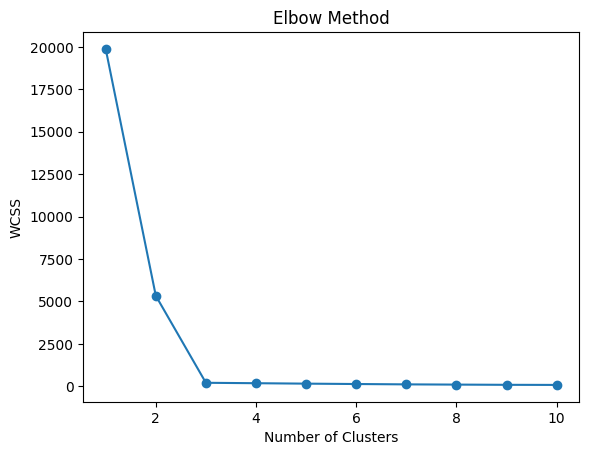

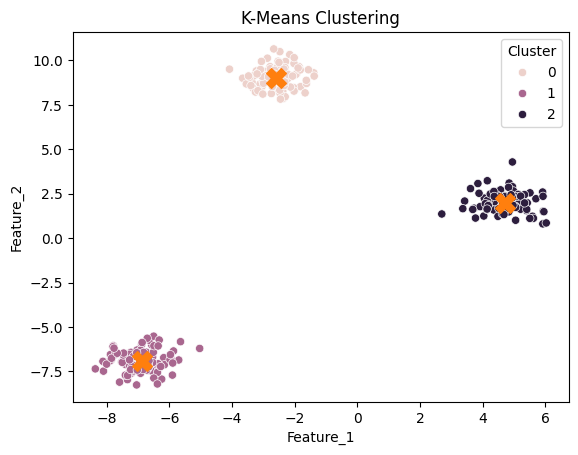

K-Means Silhouette Score: 0.908
--- Part 2: PCA ---
        PC1       PC2  True_Cluster
0  0.455305  1.623917             3
1 -2.705622  0.375012             1
2  0.810234  1.966926             3
3  0.427139  2.149626             3
4 -2.407508  0.099250             1
Explained Variance Ratio: [0.57208431 0.33622342]
Total Explained Variance: 0.908


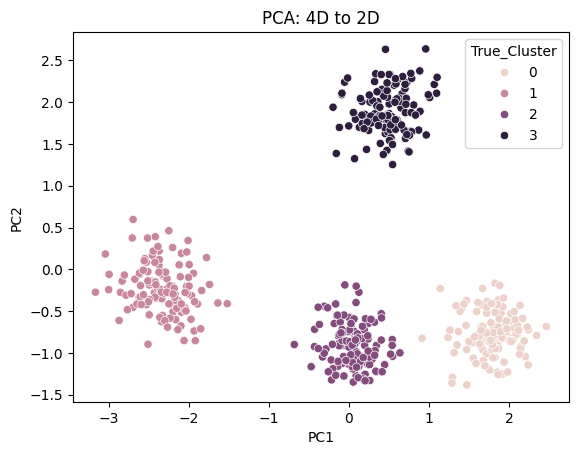

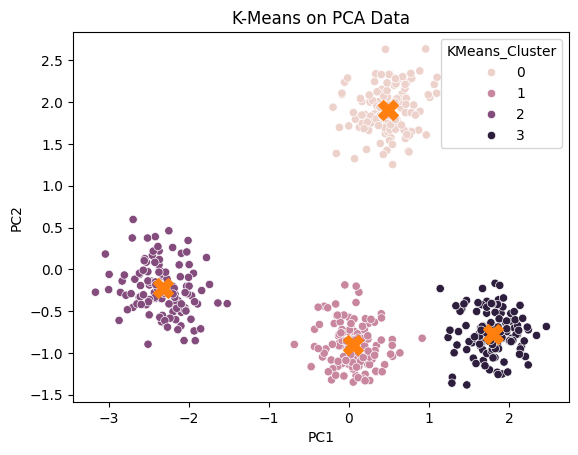

PCA K-Means Silhouette Score: 0.776


In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

print("--- Part 1: K-Means Clustering ---")
X, y = make_blobs(n_samples=300, centers=3, cluster_std=0.60, random_state=42)
df_kmeans = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])
print(df_kmeans.head())

wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, n_init=10, random_state=42)
    km.fit(X)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X)
df_kmeans['Cluster'] = clusters
sns.scatterplot(data=df_kmeans, x='Feature_1', y='Feature_2', hue='Cluster')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker='X', s=200)
plt.title('K-Means Clustering')
plt.show()
print("K-Means Silhouette Score:", round(silhouette_score(X, clusters), 3))
print("--- Part 2: PCA ---")
X_pca, y_pca = make_blobs(n_samples=500, n_features=4, centers=4, random_state=25)
X_scaled = StandardScaler().fit_transform(X_pca)
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)
df = pd.DataFrame(components, columns=['PC1', 'PC2'])
df['True_Cluster'] = y_pca
print(df.head())
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Explained Variance:", round(pca.explained_variance_ratio_.sum(), 3))
sns.scatterplot(data=df, x='PC1', y='PC2', hue='True_Cluster')
plt.title('PCA: 4D to 2D')
plt.show()
km_pca = KMeans(n_clusters=4, n_init=10, random_state=42)
clusters_pca = km_pca.fit_predict(components)
df['KMeans_Cluster'] = clusters_pca
sns.scatterplot(data=df, x='PC1', y='PC2', hue='KMeans_Cluster')
plt.scatter(km_pca.cluster_centers_[:, 0], km_pca.cluster_centers_[:, 1], marker='X', s=200)
plt.title('K-Means on PCA Data')
plt.show()
print("PCA K-Means Silhouette Score:", round(silhouette_score(components, clusters_pca), 3))
